# Model Evaluation, Generalization, and Error Analysis

**A practical lesson on evaluating models honestly, understanding classification metrics, and investigating mistakes.**

The previous notebooks introduced deep learning, neural networks, PyTorch, training, CNNs, and transfer learning. Now we ask: **how can we tell whether a model will work on data it has never seen?**

We will create a reproducible synthetic binary-classification dataset, train a small PyTorch model, compare it with baselines, plot evaluation curves, and inspect errors. The data are synthetic and demonstrate methods only; they are not evidence of real-world or clinical performance.

## 1. Learning objectives

By the end, you should be able to:
- Explain the roles of training, validation, and test sets.
- Describe generalization, underfitting, overfitting, and data leakage.
- Calculate and interpret a confusion matrix.
- Explain accuracy, precision, recall, specificity, F1, ROC-AUC, and average precision.
- Evaluate a PyTorch model using `model.eval()` and `torch.no_grad()`.
- Explain how decision thresholds affect predictions.
- Compare models fairly and investigate incorrect predictions.

**Prerequisites:** basic Python, NumPy, plotting, scikit-learn, and the PyTorch concepts covered in earlier notebooks.

## 2. Imports and reproducibility

We set random seeds to make the experiment more repeatable. Exact reproducibility across hardware, library versions, and nondeterministic operations is not guaranteed.

In [1]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
import sklearn

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report, roc_curve,
    roc_auc_score, precision_recall_curve, average_precision_score
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("scikit-learn:", sklearn.__version__)
print("Device:", device)

PyTorch: 2.5.1+cu121
scikit-learn: 1.9.0
Device: cuda


## 3. Training, validation, and test sets

- **Training set:** used to learn model parameters.
- **Validation set:** used for development choices, such as model selection, hyperparameter tuning, and threshold selection.
- **Test set:** reserved for final evaluation after development decisions are complete.

Repeatedly choosing models based on test results turns the test set into part of development and can make the final score overly optimistic.

Stratification can preserve class proportions for ordinary i.i.d. data. Related samples (such as multiple images from one patient) may need group-based splitting; time-series data often needs chronological splitting.

### 3.1 Create and split a teaching dataset

We use synthetic data so the notebook runs without downloading a dataset. Class proportions are intentionally unequal to demonstrate why accuracy alone can mislead.

,Split,Samples,Class 0,Class 1
0,Train,2400,1713,687
1,Validation,800,571,229
2,Test,800,571,229


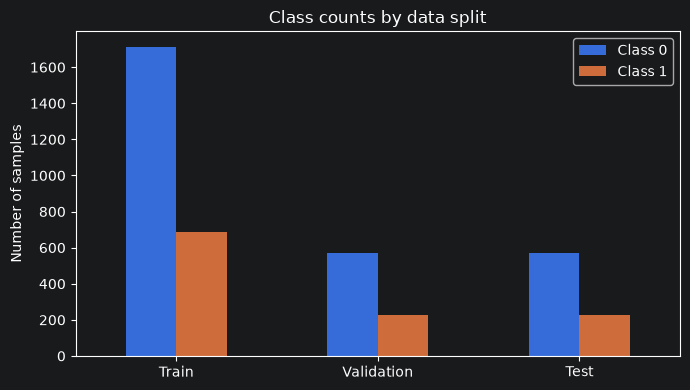

In [3]:
X, y = make_classification(
    n_samples=4000, n_features=12, n_informative=7, n_redundant=3,
    n_classes=2, weights=[0.72, 0.28], class_sep=1.0,
    flip_y=0.03, random_state=SEED
)

# Hold out the final test set first.
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)
# Split the remaining development data into training and validation.
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=SEED
)

summary = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Samples": [len(y_train), len(y_val), len(y_test)],
    "Class 0": [(y_train == 0).sum(), (y_val == 0).sum(), (y_test == 0).sum()],
    "Class 1": [(y_train == 1).sum(), (y_val == 1).sum(), (y_test == 1).sum()],
})
display(summary)

summary.set_index("Split")[["Class 0", "Class 1"]].plot(
    kind="bar", figsize=(7, 4), title="Class counts by data split"
)
plt.ylabel("Number of samples")
plt.xlabel("")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 4. Data leakage and preprocessing

**Data leakage** occurs when information unavailable at prediction time influences model fitting or model selection. It can make evaluation results look better than real performance.

For standardization,

$$
z = \\frac{x - \\mu_{\\text{train}}}{\\sigma_{\\text{train}}}
$$

Learn the mean and standard deviation from training data only. Apply the same learned transformation to validation and test data.

In [4]:
scaler = StandardScaler()

# Learn scaling parameters from training data only.
X_train_scaled = scaler.fit_transform(X_train)

# Apply the learned transformation to the other splits.
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Train means (first 4):", np.round(X_train_scaled.mean(axis=0)[:4], 3))
print("Validation means (first 4):", np.round(X_val_scaled.mean(axis=0)[:4], 3))

Train means (first 4): [-0. -0. -0.  0.]
Validation means (first 4): [-0.001 -0.024  0.063 -0.078]


Validation feature means do not need to be exactly zero: the scaler was fitted only on training data. Other leakage risks include duplicate samples across splits, selecting features using the complete dataset, using future information, or repeatedly adjusting the model based on test results. Scikit-learn `Pipeline` objects help keep preprocessing and fitting together during cross-validation.

## 5. Generalization, underfitting, and overfitting

**Generalization** is the ability to perform well on new examples from the population of interest.

- **Underfitting:** the model has not learned enough useful structure; training and validation performance may both be poor.
- **Overfitting:** the model fits training-specific patterns that do not transfer; training performance improves while validation performance stalls or worsens.

A descriptive generalization gap is:

$$
\\Delta_{\\text{generalization}} =
L_{\\text{validation}} - L_{\\text{training}}
$$

This gap is not a universal overfitting test; interpret it in context.

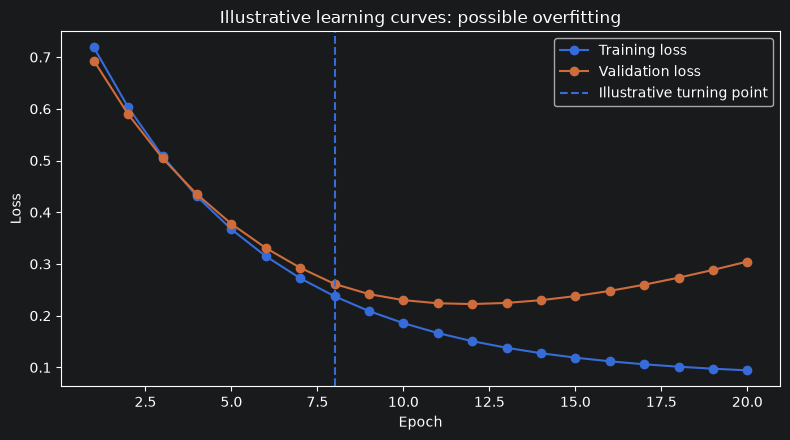

In [5]:
# Illustrative values only—not measured model output.
epochs = np.arange(1, 21)
train_demo = 0.78 * np.exp(-epochs / 5) + 0.08
val_demo = 0.70 * np.exp(-epochs / 5) + 0.12 + 0.006 * np.maximum(epochs - 8, 0) ** 1.35

plt.figure(figsize=(8, 4.5))
plt.plot(epochs, train_demo, marker="o", label="Training loss")
plt.plot(epochs, val_demo, marker="o", label="Validation loss")
plt.axvline(8, linestyle="--", label="Illustrative turning point")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Illustrative learning curves: possible overfitting")
plt.legend()
plt.tight_layout()
plt.show()

The illustrative plot shows training loss falling while validation loss eventually rises. In real work, use recorded losses. Potential responses include collecting representative data, simplifying the model, regularization, appropriate augmentation, or choosing a checkpoint using validation performance.

## 6. Confusion Matrix: The Building Blocks

A **confusion matrix** summarizes the performance of a classification model by comparing predicted labels with the actual labels.

- **True Positive (TP):** The model predicts positive, and the actual label is positive.
- **True Negative (TN):** The model predicts negative, and the actual label is negative.
- **False Positive (FP):** The model predicts positive, but the actual label is negative.
- **False Negative (FN):** The model predicts negative, but the actual label is positive.

For binary classification, when the labels are ordered as `[0, 1]`, scikit-learn returns the following confusion matrix:

$$
\begin{bmatrix}
TN & FP \\
FN & TP
\end{bmatrix}
$$

**How to read the matrix:**

- Rows represent the **true (actual) labels**.
- Columns represent the **predicted labels**.
- Label `0` typically represents the negative class, and label `1` represents the positive class.

In scikit-learn, the confusion matrix is defined as \(C_{i,j}\), where \(i\) is the true class and \(j\) is the predicted class.

**Important:** Always verify the label order and the positive class before interpreting a confusion matrix, especially when working with imbalanced datasets.

## 7. Classification Metrics: The Mathematics

Classification metrics evaluate different aspects of a model's performance. Using the confusion matrix values (TP, TN, FP, FN), we can calculate the following metrics.

### 7.1 Accuracy

$$
\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}
$$

**Definition:** The proportion of all predictions that are correct.

**Limitation:** On imbalanced datasets, a model can achieve high accuracy by predicting only the majority class while failing to identify minority-class examples.

### 7.2 Precision

$$
\text{Precision} = \frac{TP}{TP + FP}
$$

**Definition:** The proportion of predicted-positive examples that are actually positive.

**Interpretation:** High precision means fewer false positives.

### 7.3 Recall (Sensitivity)

$$
\text{Recall} = \text{Sensitivity} = \frac{TP}{TP + FN}
$$

**Definition:** The proportion of actual positive examples correctly identified by the model.

**Interpretation:** High recall means fewer false negatives.

### 7.4 Specificity

$$
\text{Specificity} = \frac{TN}{TN + FP}
$$

**Definition:** The proportion of actual negative examples correctly identified by the model.

**Interpretation:** High specificity means fewer false positives among actual negative examples.

### 7.5 F1 Score

$$
F_1 = 2 \cdot
\frac{\text{Precision}\cdot\text{Recall}}
{\text{Precision}+\text{Recall}}
$$

**Definition:** The harmonic mean of precision and recall.

**Interpretation:** F1 balances precision and recall, making it useful when the positive class is particularly important. Unlike accuracy, F1 does not directly incorporate true negatives.

### 7.6 Balanced Accuracy

$$
\text{Balanced Accuracy} =
\frac{\text{Sensitivity}+\text{Specificity}}{2}
$$

**Definition:** The arithmetic mean of sensitivity and specificity in binary classification.

**Interpretation:** Balanced accuracy gives equal weight to the positive and negative classes, making it useful for evaluating models on imbalanced datasets.

### Important Implementation Notes

- **Zero denominators:** Precision is undefined when \(TP+FP=0\); recall is undefined when \(TP+FN=0\); specificity is undefined when \(TN+FP=0\). F1 is also undefined when precision and recall are both zero under the mathematical definition.
- **Implementation behavior:** Libraries such as scikit-learn provide configurable handling of undefined metrics through parameters such as `zero_division`.
- **Metric selection:** Choose metrics based on the task, class distribution, and relative costs of false positives and false negatives. In medical screening, for example, recall may be especially important when missing a positive case is costly.

## 8. Train a small PyTorch model

We train a compact multilayer perceptron (MLP) to generate real predictions for the evaluation exercises. The aim is to understand evaluation, not to optimize a benchmark.

In [6]:
# Convert scaled features and labels to tensors.
X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
X_val_t = torch.tensor(X_val_scaled, dtype=torch.float32)
X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)
y_val_t = torch.tensor(y_val, dtype=torch.float32).view(-1, 1)

train_loader = DataLoader(
    TensorDataset(X_train_t, y_train_t), batch_size=64, shuffle=True
)
val_loader = DataLoader(
    TensorDataset(X_val_t, y_val_t), batch_size=128, shuffle=False
)

class BinaryMLP(nn.Module):
    """MLP returning one logit per sample for binary classification."""
    def __init__(self, input_features):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_features, 32),
            nn.ReLU(),
            nn.Dropout(0.15),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 1),
        )

    def forward(self, x):
        # Return raw logits; BCEWithLogitsLoss applies sigmoid internally.
        return self.network(x)

model = BinaryMLP(X_train_t.shape[1]).to(device)
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
print(model)

BinaryMLP(
  (network): Sequential(
    (0): Linear(in_features=12, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.15, inplace=False)
    (3): Linear(in_features=32, out_features=16, bias=True)
    (4): ReLU()
    (5): Linear(in_features=16, out_features=1, bias=True)
  )
)


### Why logits and `BCEWithLogitsLoss`?

A logit is an unbounded real-valued score. Sigmoid converts it to a probability:

$$
p(y=1\\mid x)=\\sigma(z)=\\frac{1}{1+e^{-z}}
$$

`BCEWithLogitsLoss` combines sigmoid and binary cross-entropy in a numerically stable operation. Pass raw logits to this loss; apply sigmoid when probabilities are needed.

Epoch 01 | train=0.6106 | val=0.5604
Epoch 05 | train=0.3308 | val=0.2938
Epoch 10 | train=0.2529 | val=0.2285
Epoch 15 | train=0.2250 | val=0.2121
Epoch 20 | train=0.2182 | val=0.2051
Epoch 25 | train=0.2023 | val=0.1999
Epoch 30 | train=0.1900 | val=0.1969
Best validation loss: 0.1969


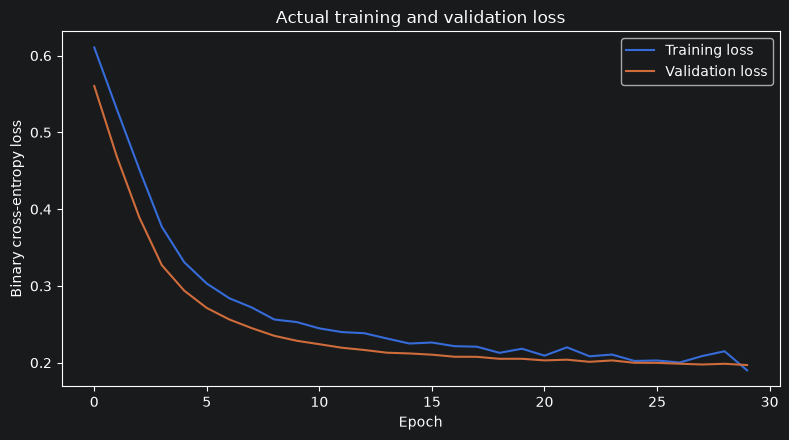

In [7]:
def run_epoch(model, loader, loss_fn, optimizer=None):
    """Run one training or validation epoch and return mean sample loss."""
    training = optimizer is not None
    model.train() if training else model.eval()
    total_loss, total_samples = 0.0, 0

    # Gradients are enabled during training and disabled during validation.
    with torch.set_grad_enabled(training):
        for features, labels in loader:
            features, labels = features.to(device), labels.to(device)
            logits = model(features)
            loss = loss_fn(logits, labels)

            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            n = len(features)
            total_loss += loss.item() * n
            total_samples += n

    return total_loss / total_samples


history = {"train_loss": [], "val_loss": []}
best_val_loss, best_state = float("inf"), None
patience, stale_epochs = 6, 0

for epoch in range(30):
    train_loss = run_epoch(model, train_loader, loss_fn, optimizer)
    val_loss = run_epoch(model, val_loader, loss_fn)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        stale_epochs = 0
    else:
        stale_epochs += 1

    if epoch == 0 or (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch+1:02d} | train={train_loss:.4f} | val={val_loss:.4f}")
    if stale_epochs >= patience:
        print(f"Early stopping at epoch {epoch+1}")
        break

# Restore the checkpoint selected by validation loss.
model.load_state_dict(best_state)
model.to(device)
print(f"Best validation loss: {best_val_loss:.4f}")

plt.figure(figsize=(8, 4.5))
plt.plot(history["train_loss"], label="Training loss")
plt.plot(history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy loss")
plt.title("Actual training and validation loss")
plt.legend()
plt.tight_layout()
plt.show()

## 9. Correct PyTorch evaluation

- `model.eval()` switches layers such as Dropout and Batch Normalization to evaluation behavior.
- `torch.no_grad()` disables gradient tracking, reducing unnecessary computation and memory use during inference.

They serve different purposes. `model.eval()` does not disable gradients by itself, and `torch.no_grad()` does not switch Dropout or Batch Normalization behavior.

In [8]:
@torch.no_grad()
def predict_probabilities(model, features):
    """Return positive-class probabilities from a tensor of features."""
    model.eval()
    logits = model(features.to(device))
    return torch.sigmoid(logits).squeeze(1).cpu().numpy()

# Validation predictions support development decisions.
val_probabilities = predict_probabilities(model, X_val_t)

# Test probabilities are for final evaluation, not threshold tuning.
test_probabilities = predict_probabilities(model, X_test_t)
print(np.round(test_probabilities[:10], 3))

[0.173 0.002 0.032 0.987 0.    0.077 0.955 0.016 0.978 0.004]


## 10. Confusion matrix and metrics

A predicted probability becomes a class label only after a threshold is applied. Here, class `1` is explicitly the positive class.

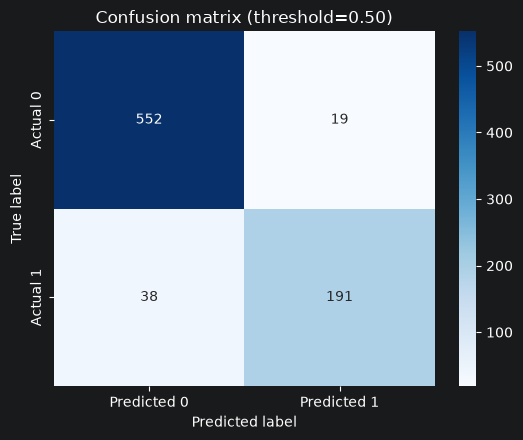

TN=552, FP=19, FN=38, TP=191


,Test result
Accuracy,0.929
Balanced accuracy,0.900
Precision,0.910
Recall / sensitivity,0.834
Specificity,0.967
F1,0.870
ROC-AUC,0.965
Average precision,0.948


                    precision    recall  f1-score   support

Class 0 (negative)      0.936     0.967     0.951       571
Class 1 (positive)      0.910     0.834     0.870       229

          accuracy                          0.929       800
         macro avg      0.923     0.900     0.911       800
      weighted avg      0.928     0.929     0.928       800



In [9]:
THRESHOLD = 0.50
test_predictions = (test_probabilities >= THRESHOLD).astype(int)
cm = confusion_matrix(y_test, test_predictions, labels=[0, 1])

plt.figure(figsize=(5.5, 4.5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Predicted 0", "Predicted 1"],
    yticklabels=["Actual 0", "Actual 1"]
)
plt.title(f"Confusion matrix (threshold={THRESHOLD:.2f})")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")

def binary_metrics(y_true, y_pred, scores=None):
    """Calculate common binary metrics for positive class 1."""
    matrix = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = matrix.ravel()
    results = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced accuracy": balanced_accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall / sensitivity": recall_score(y_true, y_pred, zero_division=0),
        "Specificity": tn / (tn + fp) if (tn + fp) else np.nan,
        "F1": f1_score(y_true, y_pred, zero_division=0),
    }
    if scores is not None:
        results["ROC-AUC"] = roc_auc_score(y_true, scores)
        results["Average precision"] = average_precision_score(y_true, scores)
    return pd.Series(results)

display(binary_metrics(y_test, test_predictions, test_probabilities).to_frame("Test result").round(3))
print(classification_report(
    y_test, test_predictions, labels=[0, 1],
    target_names=["Class 0 (negative)", "Class 1 (positive)"],
    zero_division=0, digits=3
))

`Support` in the classification report is the number of true samples in each class. Macro averages treat classes equally; weighted averages weight classes by support. With imbalanced data, inspect per-class results instead of relying only on a weighted average.

## 11. ROC curve and ROC-AUC

The Receiver Operating Characteristic (ROC) curve plots the true positive rate against the false positive rate at different thresholds:

$$
\\text{TPR}=\\frac{TP}{TP+FN},
\\qquad
\\text{FPR}=\\frac{FP}{FP+TN}=1-\\text{Specificity}
$$

ROC-AUC summarizes ranking performance across thresholds. It does not choose a threshold and does not guarantee that probabilities are calibrated.

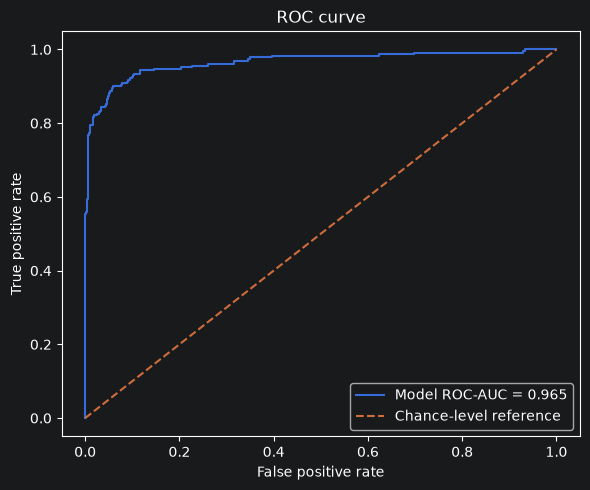

In [10]:
fpr, tpr, _ = roc_curve(y_test, test_probabilities)
roc_auc = roc_auc_score(y_test, test_probabilities)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"Model ROC-AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], "--", label="Chance-level reference")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 12. Precision-recall curve

A precision-recall curve shows how precision and recall trade off as the threshold changes. It is often especially informative when the positive class is rare. Average precision summarizes the curve, but is not identical to trapezoidal area under the plotted curve.

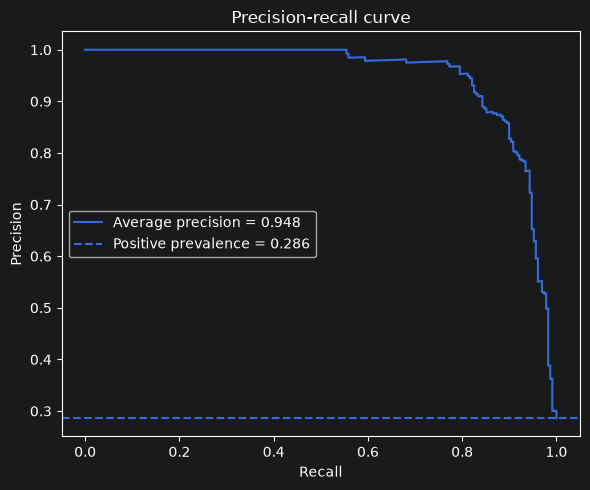

In [11]:
precision_values, recall_values, _ = precision_recall_curve(y_test, test_probabilities)
avg_precision = average_precision_score(y_test, test_probabilities)
prevalence = np.mean(y_test)

plt.figure(figsize=(6, 5))
plt.plot(recall_values, precision_values, label=f"Average precision = {avg_precision:.3f}")
plt.axhline(prevalence, linestyle="--", label=f"Positive prevalence = {prevalence:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-recall curve")
plt.legend()
plt.tight_layout()
plt.show()

## 13. Decision Thresholds

A classification model may output a probability rather than a class label. A **decision threshold** converts this probability into a predicted class.

$$
\hat{y} =
\begin{cases}
1, & \text{if } p(y=1\mid x)\geq t \\
0, & \text{if } p(y=1\mid x)<t
\end{cases}
$$

Where:

- $p(y=1\mid x)$ is the predicted probability of the positive class.
- $t$ is the decision threshold, typically between 0 and 1.
- $\hat{y}$ is the predicted class label.

### How the Threshold Affects Performance

The default threshold of `0.5` is common, but it is not necessarily optimal for every classification task.

- **Lower threshold:** Typically increases recall (sensitivity) while potentially reducing precision.
- **Higher threshold:** Typically increases precision while potentially reducing recall.

These are general tendencies, not guarantees; the actual effects depend on the model's predicted probabilities and the data.

### Selecting a Threshold

1. Generate predicted probabilities on the validation set.
2. Evaluate candidate thresholds using a predefined objective, such as maximizing F1 or achieving a target recall.
3. Select the threshold that meets the objective and any relevant constraints.
4. Lock the threshold before evaluating the final test set.

**Important:** Do not tune the threshold on the test set. Doing so introduces test-set information into model selection and can produce an overly optimistic performance estimate.

,Threshold,Precision,Recall,F1,Predicted positive (%)
0,0.20,0.755,0.930,0.834,35.250
1,0.35,0.859,0.904,0.881,30.125
2,0.50,0.892,0.825,0.857,26.500
3,0.65,0.957,0.782,0.861,23.375
4,0.80,0.994,0.721,0.835,20.750


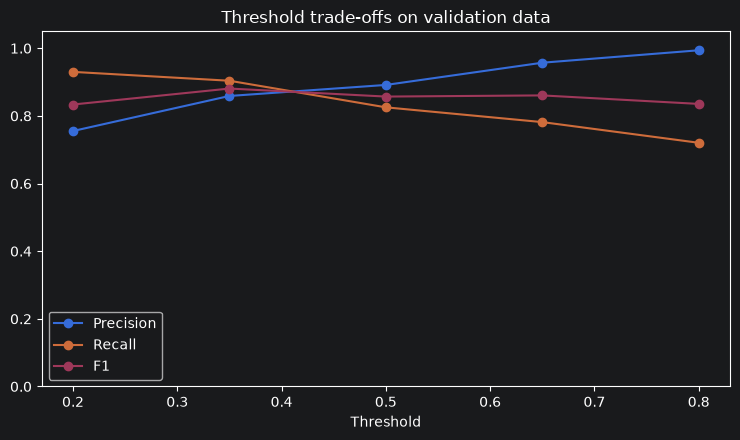

In [12]:
thresholds = [0.20, 0.35, 0.50, 0.65, 0.80]
rows = []
for threshold in thresholds:
    pred = (val_probabilities >= threshold).astype(int)
    rows.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val, pred, zero_division=0),
        "Recall": recall_score(y_val, pred, zero_division=0),
        "F1": f1_score(y_val, pred, zero_division=0),
        "Predicted positive (%)": 100 * pred.mean(),
    })

threshold_table = pd.DataFrame(rows)
display(threshold_table.round(3))
threshold_table.plot(
    x="Threshold", y=["Precision", "Recall", "F1"],
    marker="o", figsize=(7.5, 4.5), ylim=(0, 1.05),
    title="Threshold trade-offs on validation data"
)
plt.tight_layout()
plt.show()

Threshold choice depends on false-positive and false-negative costs, class prevalence, operational constraints, and calibration. In high-stakes settings, threshold decisions require domain expertise and external validation; this classroom example is not a clinical decision rule.

## 14. Class imbalance and baseline comparison

A model can achieve high accuracy by favoring the majority class. Compare the neural network with a most-frequent baseline and logistic regression. All models use the same training and test partitions; the logistic-regression pipeline fits scaling only on training data.

In [13]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)

logistic = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=SEED)
)
logistic.fit(X_train, y_train)
logistic_pred = logistic.predict(X_test)
logistic_prob = logistic.predict_proba(X_test)[:, 1]

comparison = pd.DataFrame({
    "Most-frequent baseline": binary_metrics(y_test, dummy_pred),
    "Logistic regression": binary_metrics(y_test, logistic_pred, logistic_prob),
    "PyTorch MLP": binary_metrics(y_test, test_predictions, test_probabilities),
}).T
display(comparison.round(3))

,Accuracy,Average precision,Balanced accuracy,F1,Precision,ROC-AUC,Recall / sensitivity,Specificity
Most-frequent baseline,0.714,NaN,0.500,0.000,0.000,NaN,0.000,1.000
Logistic regression,0.840,0.808,0.774,0.689,0.776,0.889,0.620,0.928
PyTorch MLP,0.929,0.948,0.900,0.870,0.910,0.965,0.834,0.967


A neural network is not automatically better than a simpler model. Compare task-relevant metrics, computational cost, stability, and maintenance complexity. If models are tuned repeatedly, use validation data or cross-validation for development and reserve the test set for a final estimate.

## 15. Error analysis: investigate incorrect predictions

Aggregate scores do not show which examples fail. Error analysis may reveal ambiguous examples, noisy labels, missing features, subgroup weaknesses, or a mismatch between training and deployment data. These features are synthetic and have no meaningful real-world interpretation.

,Count
error_type,
Correct,743
False negative,38
False positive,19


,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,feature_11,true_label,predicted_label,probability,error_type,distance_from_threshold
684,-0.059913,1.597164,-2.464365,1.031473,0.432151,-0.331987,0.409793,-2.194299,-1.652588,-0.472362,1.004409,1.943126,1,0,0.497705,False negative,0.002295
630,-0.750973,0.804401,-1.538417,0.936062,-0.543397,-1.491214,0.066320,-0.819770,-1.319612,-0.686320,1.763146,0.409442,0,1,0.503351,False positive,0.003351
72,1.952387,0.103348,-1.091492,-0.727927,-1.999158,1.022779,-0.161427,-3.902923,-1.096469,-0.621157,-0.836930,3.924592,1,0,0.490299,False negative,0.009701
280,0.159932,1.415094,-1.666125,0.449015,0.867912,-0.572845,-0.990434,-1.667409,0.373071,-1.599212,0.304130,2.787180,0,1,0.529247,False positive,0.029247
20,0.635900,0.773775,-2.000267,0.641293,0.218809,0.537470,-0.907462,-0.693234,-1.961027,-0.476342,0.929900,1.066866,0,1,0.531075,False positive,0.031075
89,0.763587,0.419662,-1.807525,1.006522,-2.098343,-0.717860,-0.878516,-1.518429,-0.678478,-1.561880,0.657365,1.462015,1,0,0.453821,False negative,0.046179
761,-0.211192,-0.028656,-0.604253,-0.060655,0.401795,-0.559657,-1.035336,-0.148700,-1.602885,-0.238374,1.407501,0.192033,0,1,0.551386,False positive,0.051386
106,0.383813,0.167156,0.192462,0.872939,1.910675,6.604168,-0.189837,1.187913,-4.923325,5.396128,-3.621097,-0.911316,1,0,0.434401,False negative,0.065599
120,-0.104952,1.919145,-1.588455,-0.546775,-1.034007,-0.336182,-1.446045,-1.303647,0.571726,-0.728105,1.114388,1.956857,0,1,0.566166,False positive,0.066166
223,1.479582,0.268247,-2.051489,0.687285,0.455934,1.366664,-1.742810,-1.271083,-2.664892,-0.161282,0.313405,1.215987,0,1,0.576773,False positive,0.076773


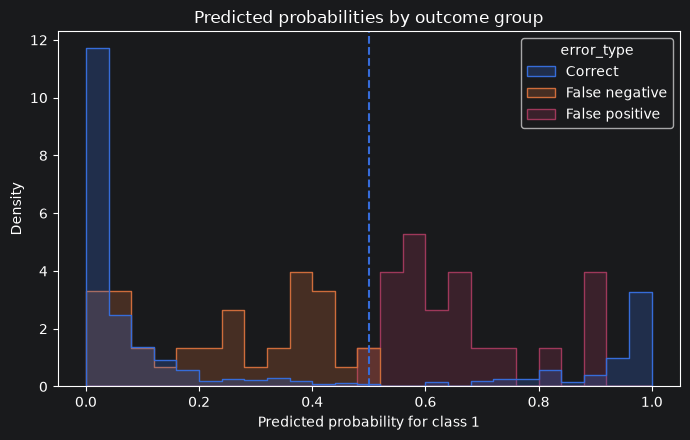

In [14]:
error_table = pd.DataFrame(
    X_test, columns=[f"feature_{i}" for i in range(X_test.shape[1])]
)
error_table["true_label"] = y_test
error_table["predicted_label"] = test_predictions
error_table["probability"] = test_probabilities

error_table["error_type"] = np.select(
    [
        (error_table.true_label == 0) & (error_table.predicted_label == 1),
        (error_table.true_label == 1) & (error_table.predicted_label == 0),
    ],
    ["False positive", "False negative"],
    default="Correct",
)
display(error_table["error_type"].value_counts().to_frame("Count"))

errors = error_table[error_table.error_type != "Correct"].copy()
errors["distance_from_threshold"] = (errors.probability - THRESHOLD).abs()
display(errors.sort_values("distance_from_threshold").head(10))

plt.figure(figsize=(7, 4.5))
sns.histplot(
    data=error_table, x="probability", hue="error_type",
    bins=25, element="step", stat="density", common_norm=False
)
plt.axvline(THRESHOLD, linestyle="--", label="Decision threshold")
plt.xlabel("Predicted probability for class 1")
plt.title("Predicted probabilities by outcome group")
plt.tight_layout()
plt.show()

Questions for error analysis:
1. Are false negatives more costly than false positives?
2. Do errors cluster near the threshold?
3. Are some meaningful subgroups evaluated less well?
4. Could a feature be missing, noisy, or only available after the event?
5. Are labels consistent and reliable?
6. Would more representative data help, or is the model learning the wrong signal?

Changing the threshold will not fix every problem.

## 16. Fair comparison and reproducibility

A useful comparison should:
- Use the same data splits and target definition.
- Fit preprocessing only on training data.
- Tune models and thresholds on validation data or cross-validation.
- Report relevant metrics, not only the most flattering score.
- Consider variability across splits or seeds, especially on small datasets.
- Record model settings, software versions, and hardware.
- Use group-based splitting for related samples and chronological splitting for time-series data where appropriate.

Cross-validation can help estimate variability during development, but it must match the data structure and does not remove the need for a suitable final test set.

In [15]:
display(pd.Series({
    "PyTorch": torch.__version__,
    "scikit-learn": sklearn.__version__,
    "NumPy": np.__version__,
    "pandas": pd.__version__,
    "Device": str(device),
    "Random seed": SEED,
}, name="Value").to_frame())

,Value
PyTorch,2.5.1+cu121
scikit-learn,1.9.0
NumPy,2.4.6
pandas,2.3.3
Device,cuda
Random seed,42


## 17. Common evaluation mistakes

- Using the test set to choose a model or threshold.
- Reporting accuracy alone on imbalanced data.
- Forgetting which class is positive.
- Fitting preprocessing on all data before splitting.
- Splitting correlated samples across training and test sets.
- Using `model.train()` during evaluation.
- Forgetting `torch.no_grad()` during inference.
- Comparing models on different splits.
- Treating ROC-AUC as a decision threshold.
- Assuming validation performance guarantees deployment performance.
- Treating synthetic classroom results as evidence for clinical use.

## 18. Practical exercises

1. **Threshold experiment:** use validation probabilities at thresholds `0.10`, `0.30`, `0.50`, `0.70`, and `0.90`. Plot precision and recall and explain the changes.
2. **Metric calculator:** write a function accepting TP, TN, FP, FN and returning accuracy, precision, recall, specificity, and F1. Handle zero denominators.
3. **Baseline comparison:** explain why the most-frequent baseline can have deceptively high accuracy.
4. **Generalization experiment:** train smaller and larger MLPs and compare actual training and validation curves.
5. **Recall target:** choose a threshold on validation data to meet a recall target, lock it, and evaluate once on test data.
6. **Error analysis:** inspect false positives and false negatives. Do not assign real-world meaning to synthetic features.
7. **Model card:** summarize intended use, dataset limitations, metrics, known failure modes, and further validation needed.

## 19. Key takeaways

- Evaluation protocol matters as much as the metric.
- Training, validation, and test data have different roles.
- Leakage can make performance estimates overly optimistic.
- Accuracy, precision, recall, specificity, F1, ROC-AUC, and average precision answer different questions.
- Thresholds should be selected using validation data and task requirements.
- Confusion matrices and error analysis reveal information a single score cannot.
- Baselines help determine whether model complexity adds value.
- A final test result should be reported honestly and not repeatedly optimized against.
- High-stakes applications require domain-appropriate validation beyond a classroom example.

## 20. Quick reference

| Question | Useful tool | Reminder |
|---|---|---|
| Fraction of predictions correct? | Accuracy | Can mislead with imbalance |
| Reliability of positive predictions? | Precision | False positives matter |
| Fraction of positives found? | Recall / sensitivity | False negatives matter |
| Fraction of negatives found? | Specificity | `1 - FPR` |
| Balance between precision and recall? | F1 | Does not directly include TN |
| Ranking across thresholds? | ROC-AUC | Does not choose a threshold |
| Precision-recall trade-off? | PR curve / average precision | Inspect for rare positives |
| Types of errors? | Confusion matrix | Check label order |
| PyTorch evaluation? | `model.eval()` + `torch.no_grad()` | Different purposes |
| Avoid preprocessing leakage? | Fit on training data / Pipeline | Transform other splits consistently |

## 21. Official references and further reading

1. **PyTorch — Optimizing Model Parameters**  
   https://docs.pytorch.org/tutorials/beginner/basics/optimization_tutorial.html  
   Training and evaluation loops, loss functions, and optimizers.

2. **PyTorch — Learn the Basics**  
   https://docs.pytorch.org/tutorials/beginner/basics/intro.html  
   End-to-end PyTorch workflow.

3. **scikit-learn — Model Evaluation**  
   https://scikit-learn.org/stable/modules/model_evaluation.html  
   Classification metrics and evaluation tools.

4. **scikit-learn — Common Pitfalls and Recommended Practices**  
   https://scikit-learn.org/stable/common_pitfalls.html  
   Data leakage, preprocessing, random states, and recommended practices.

5. **scikit-learn — `train_test_split`**  
   https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html

6. **scikit-learn — `precision_recall_curve`**  
   https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_recall_curve.html

7. **scikit-learn — `roc_auc_score`**  
   https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html

**Final note:** this notebook teaches evaluation methods. It does not claim that the synthetic-data model is suitable for real deployment. Adapt splits, metrics, thresholds, and validation protocols to the real data and the costs of different errors.